# **Практика 5. Создание AI-агента**

**Цель:** собрать AI-агента с генерацией дайджеста, Telegram-доставкой и обработкой ошибок.

## Что такое агент

Агент — это программа, которая:
1. **Сама** берёт данные из источника
2. **Сама** анализирует их (через AI)
3. **Сама** сохраняет или отправляет результат

Вы запускаете один раз → дальше работает без вас.

## На этом занятии

Мы строим **блоки агента** по одному. В конце они должны соединиться в рабочий пайплайн.

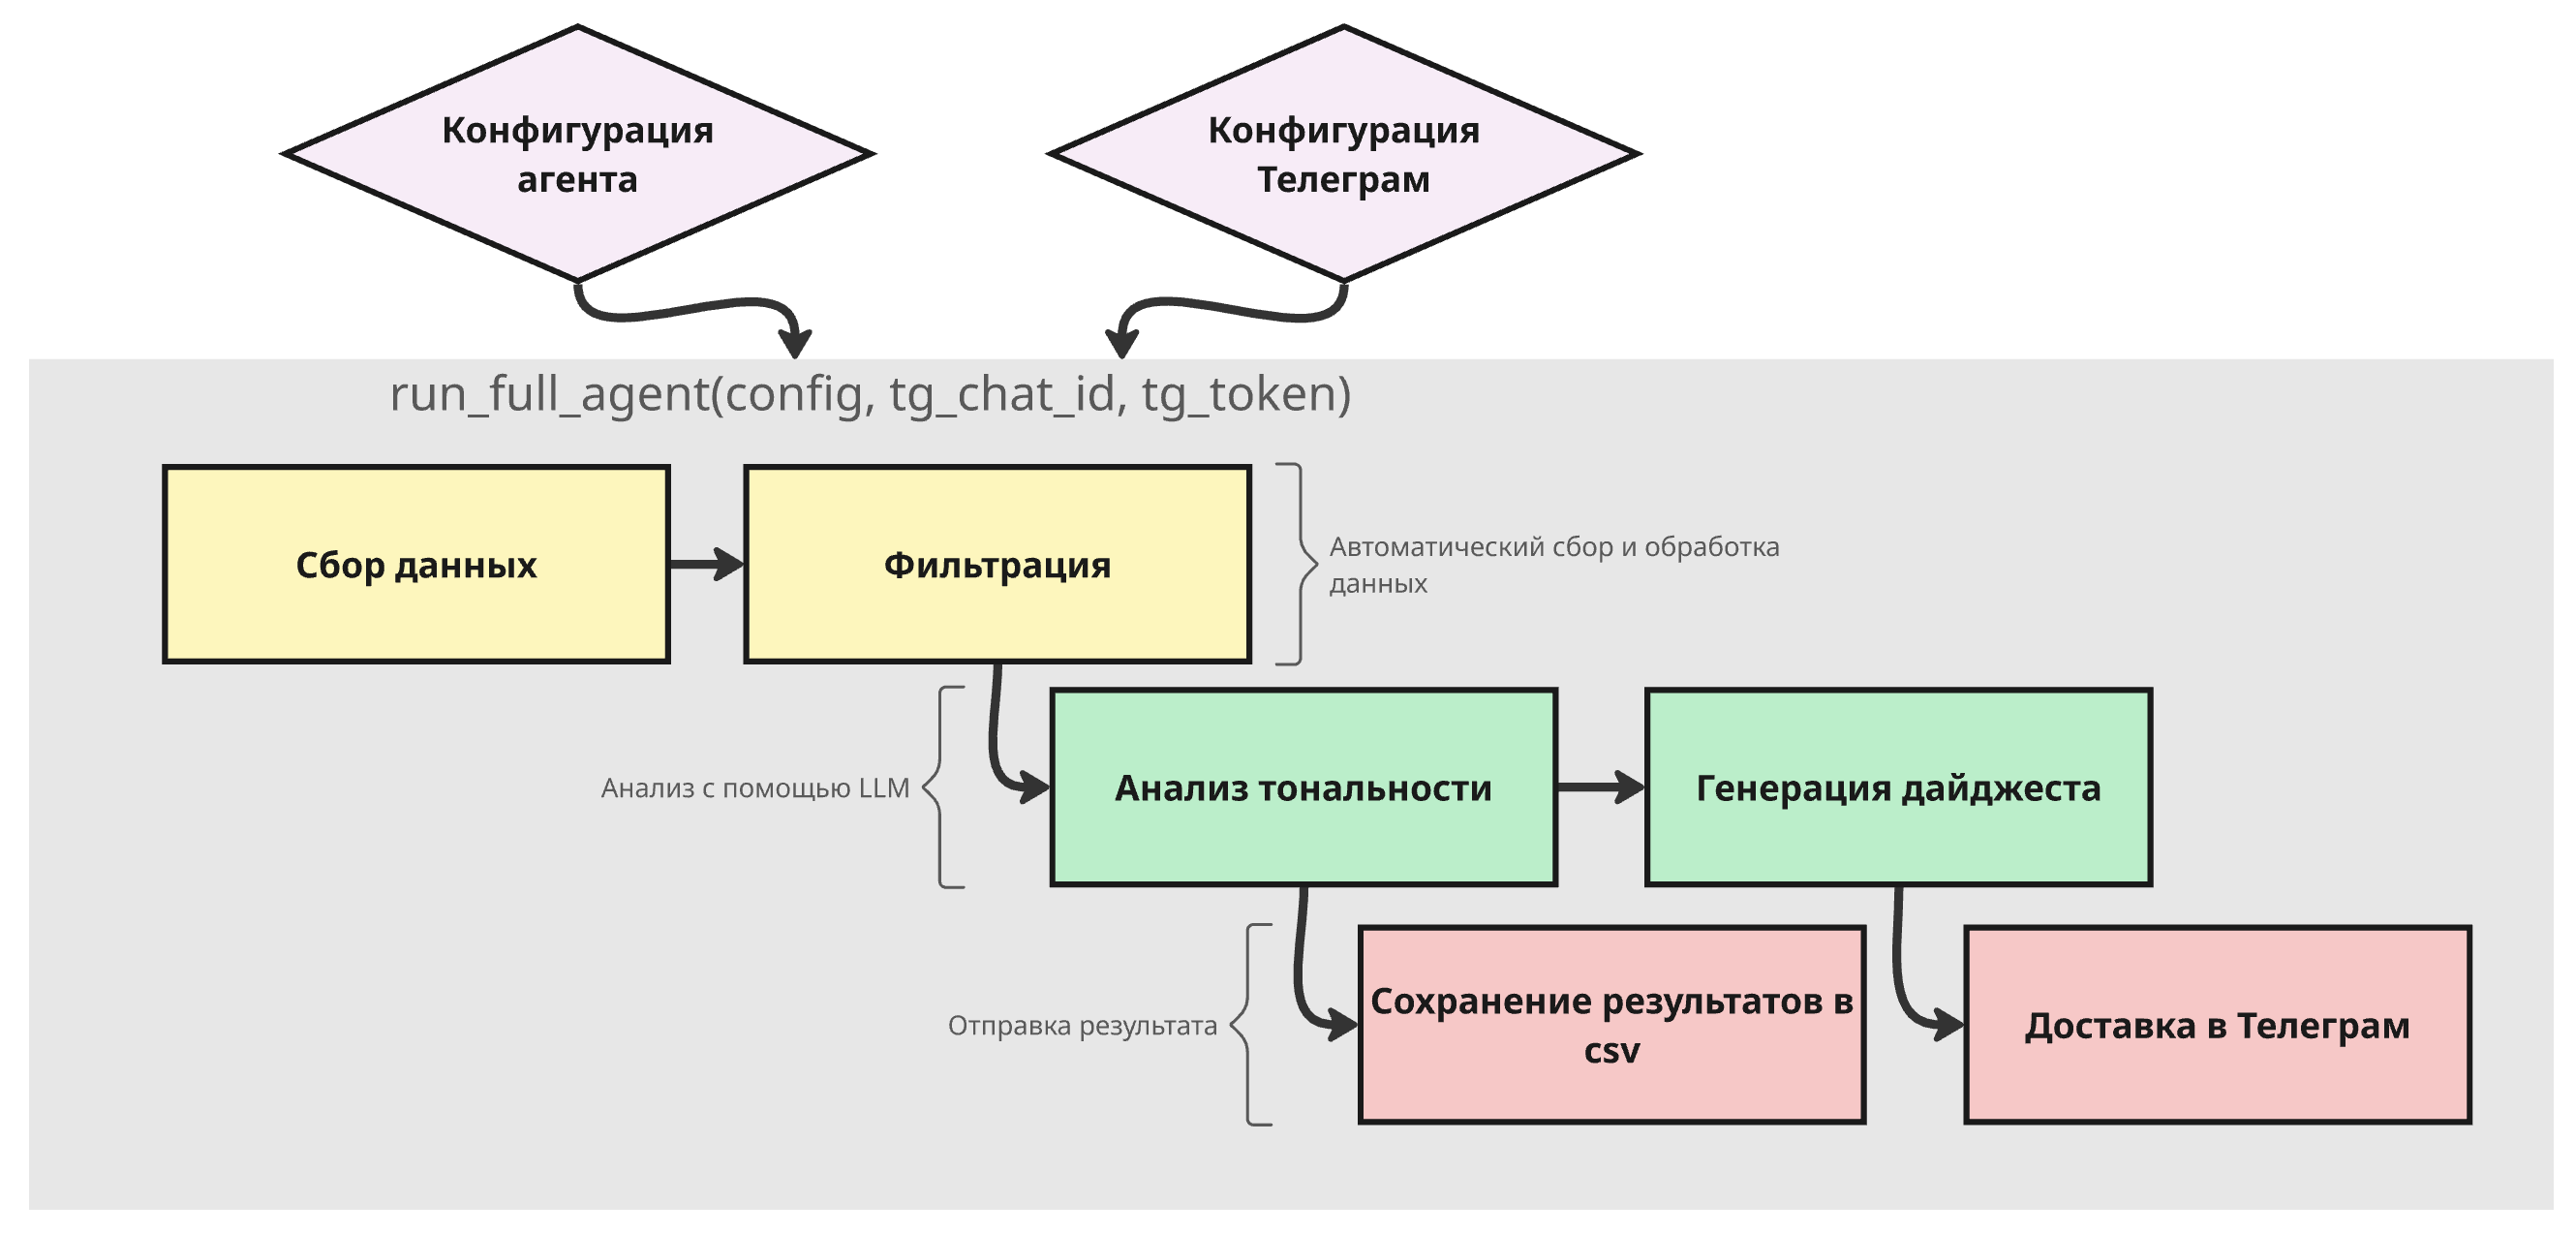

In [ ]:
!pip install feedparser google-generativeai gigachat requests -q
print("Зависимости установлены")

---
## **Шаг 0: Конфигурация агента**

Всё настраиваемое собираем в один словарь — так легко менять без поиска по коду.

In [ ]:
# ЗАДАНИЕ: Заполните конфигурацию под ваш проект

AGENT_CONFIG = {
    # Что мониторим
    "brand": "Россия",                    # ← Ваш бренд
    "keywords": ["Россию", "России", "Россия"],    # ← Ключевые слова

    # Источники данных
    "rss_feeds": [
        "https://lenta.ru/rss/news",
        "https://tass.ru/rss/v2.xml",
        # Добавьте третий источник
    ],

    # Ограничения
    "max_articles": 10,  # Максимум статей за запуск

    # API
    "api": "gigachat",  #'gigachat'
    "gigachat_creds": "ВСТАВЬТЕ КЛЮЧ",
}

In [ ]:
print(f"Агент настроен для мониторинга: {AGENT_CONFIG['brand']}")
print(f"Ключевые слова: {', '.join(AGENT_CONFIG['keywords'])}")
print(f"Источников RSS: {len(AGENT_CONFIG['rss_feeds'])}")

---
## **Блок 1: Сбор данных**

In [ ]:
import feedparser
import time

In [ ]:
def collect_news(config):
    """Блок 1: Собирает новости из всех RSS-источников."""
    all_articles = []

    for feed_url in config["rss_feeds"]:
        try:
            feed = feedparser.parse(feed_url)
            source_name = feed.feed.get('title', feed_url)

            for entry in feed.entries[:30]:
                all_articles.append({
                    'title': entry.get('title', ''),
                    'summary': entry.get('summary', '')[:400],
                    'link': entry.get('link', ''),
                    'published': entry.get('published', ''),
                    'source': source_name
                })

            time.sleep(1)

        except Exception as e:
            print(f"Ошибка при сборе из {feed_url}: {e}")

    print(f"Собрано статей: {len(all_articles)}")
    return all_articles

In [ ]:
# Запускаем
raw_articles = collect_news(AGENT_CONFIG)
print(f"Пример: {raw_articles[0]['title'][:80] if raw_articles else 'нет статей'}")

---
## **Блок 2: Фильтрация**

In [ ]:
def filter_relevant(articles, config):
    """Блок 2: Оставляет только релевантные статьи."""
    keywords_lower = [kw.lower() for kw in config['keywords']]
    relevant = []

    for article in articles:
        text = (article['title'] + ' ' + article['summary']).lower()
        if any(kw in text for kw in keywords_lower):
            relevant.append(article)

    # Ограничиваем максимальным числом
    relevant = relevant[:config['max_articles']]

    print(f"Релевантных: {len(relevant)} из {len(articles)}")
    return relevant

In [ ]:
relevant_articles = filter_relevant(raw_articles, AGENT_CONFIG)

for art in relevant_articles:
    print(art['title'])

---
## **Блок 3: AI-анализ каждой статьи**

In [ ]:
import json

In [ ]:
# Настраиваем LLM (функция з предыдущих занятий)

def ask_llm(prompt, system="Ты PR-аналитик.", temperature=0.1):
    if AGENT_CONFIG['api'] == 'gemini':
        import google.generativeai as genai
        genai.configure(api_key=AGENT_CONFIG['gemini_key'])
        model = genai.GenerativeModel('gemini-1.5-flash', system_instruction=system)
        return model.generate_content(prompt).text
    elif AGENT_CONFIG['api'] == 'gigachat':
        from gigachat import GigaChat
        from gigachat.models import Chat, Messages, MessagesRole

        with GigaChat(credentials=AGENT_CONFIG['gigachat_creds'], verify_ssl_certs=False) as giga:
            response = giga.chat(Chat(
                model="GigaChat-2", # если у вас есть оплаченные токены, модель можно поменять
                messages=[
                    Messages(role=MessagesRole.SYSTEM, content=system),
                    Messages(role=MessagesRole.USER, content=prompt)
                ],
                temperature=temperature
            ))
        return response.choices[0].message.content

In [ ]:
def analyze_article(article, brand):
    """Блок 3: Анализирует одну статью через LLM."""
    prompt = f"""Ты PR-аналитик компании {brand}. Проанализируй новость.
                 Верни ТОЛЬКО JSON без пояснений:
                 {{
                   "sentiment": "positive" или "negative" или "neutral",
                   "urgency": "high" или "medium" или "low",
                   "summary": "краткое содержание в 1-2 предложениях",
                   "pr_action": "краткая рекомендация PR-команде"
                  }}

                 Заголовок: {article['title']}
                 Содержание: {article['summary']}
                 Источник: {article['source']}
                 """

    response = ask_llm(prompt)

    try:
        clean = response.strip()
        if '```' in clean:
            clean = clean.split('```')[1]
            if clean.startswith('json'): clean = clean[4:]
        analysis = json.loads(clean)
    except:
        analysis = {'sentiment': 'neutral', 'urgency': 'low',
                    'summary': article['title'], 'pr_action': 'Мониторинг'}

    return {**article, **analysis}

In [ ]:
# Анализируем (для демо — первые 3)
analyzed = []
for art in relevant_articles[:3]:
    print(f"Анализирую статью: {art['title'][:50]}...")
    result = analyze_article(art, AGENT_CONFIG['brand'])
    analyzed.append(result)
    print(f"  → {result['sentiment']} | urgency: {result['urgency']}")
    time.sleep(0.5)

print(f"\nПроанализировано: {len(analyzed)} статей")

---
## **Блок 4: Сохранение результатов**

In [ ]:
import csv
from datetime import datetime

def save_results(analyzed_articles, config):
    """Блок 4: Сохраняет результаты в CSV."""
    if not analyzed_articles:
        print("Нет данных для сохранения")
        return None

    timestamp = datetime.now().strftime('%Y%m%d_%H%M')
    filename = f"agent_results_{config['brand']}_{timestamp}.csv"

    fieldnames = ['title', 'source', 'published', 'sentiment',
                  'urgency', 'summary', 'pr_action', 'link']

    with open(filename, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(analyzed_articles)

    print(f"Сохранено {len(analyzed_articles)} записей: {filename}")
    return filename

In [ ]:
csv_file = save_results(analyzed, AGENT_CONFIG)

if csv_file:
    from google.colab import files
    files.download(csv_file)

---
## **Блок 5: Генерация дайджеста**

In [ ]:
from datetime import datetime

In [ ]:
def generate_digest(analyzed_articles, config):

    """Блок 5: Генерирует итоговый дайджест из проанализированных статей."""

    if not analyzed_articles:
        return f" Упоминаний {config['brand']} за сегодня не найдено."

    # Формируем сводку для LLM
    articles_info = ""
    for i, art in enumerate(analyzed_articles, 1):
        articles_info += f"""[{i}] {art.get('source', '?')} | {art.get('sentiment', '?').upper()}
                             Заголовок: {art.get('title', '')}
                             Содержание: {art.get('summary', '')}
                             Рекомендация: {art.get('pr_action', '')}
                             """

    today = datetime.now().strftime("%d.%m.%Y")

    prompt = f"""Составь PR-дайджест для команды на основе новостей о компании {config['brand']}.

                 Дата: {today}
                 Новости:
                 {articles_info}

                 Формат дайджеста (строго):
                 МЕДИАДАЙДЖЕСТ {config['brand'].upper()} — {today}

                 ОБЩИЙ ТОН: [позитивный/нейтральный/негативный/смешанный]

                 ГЛАВНЫЕ НОВОСТИ:
                 • [краткое описание каждой]

                 ⚡ ТРЕБУЮТ ВНИМАНИЯ:
                 [только срочные, если есть — иначе написать "Срочных нет"]

                 РЕКОМЕНДАЦИИ:
                 [3 конкретных рекомендации для PR-команды]"""

    return ask_llm(prompt, system="Ты опытный PR-аналитик, пишешь для команды лаконично и по делу.")

In [ ]:
# Тест (используем analyzed из П6)
digest = generate_digest(analyzed, AGENT_CONFIG)
print(digest)

---

## **Блок 6: Telegram-доставка**

### **Вариант 1. Просто создание бота (для личных сообщений или тестов)**

Подойдет, если бот должен писать вам в личку или отвечать на команды.

1. Откройте Telegram → найдите **@BotFather**
2. Напишите команду `/newbot`
3. Придумайте имя (отображаемое) и username (ссылка, должна обязательно заканчиваться на `bot`, например `my_test_bot`)
4. Скопируйте полученный **токен** (сохраните его, он понадобится в коде)
5. Узнайте ваш личный `chat_id`: напишите боту **@userinfobot** команду `/start` и скопируйте ваш числовой ID.

### **Вариант 2. Создание бота для отправки сообщений в Telegram-канал**

Подойдет, если бот должен автоматически публиковать посты в ваш канал.

**Шаг 1. Создаем самого бота**
1. Откройте **@BotFather** → `/newbot` → задайте имя и username → скопируйте токен.

**Шаг 2. Добавляем бота в канал**
1. Создайте новый канал (или откройте существующий).
2. Зайдите в настройки канала → **Администраторы** → **Добавить администратора**.
3. Найдите вашего бота по username и добавьте его.  

> **ВАЖНО!** Бот обязательно должен быть назначен админом с правом «Публиковать сообщения», иначе Telegram будет выдавать ошибку.


**Шаг 3. Узнаем ID канала (или используем username)**
Чтобы бот знал, куда слать сообщения, нужен идентификатор канала. Есть два пути:
* **Путь А (для публичных каналов):** Если у канала есть публичная ссылка, просто используйте её в коде (например, `@test_channel`).
* **Путь Б (для закрытых/приватных каналов):**
  1. Перешлите любое сообщение из вашего канала боту **@userinfobot** (или **@RawDataBot**).
  2. В ответе найдите поле `Chat ID` (или `Forward from chat`).
  3. Скопируйте этот ID. Для каналов он всегда начинается с `-100` (например, `-1001234567890`).

**Итого:**
Вам понадобятся **Токен бота** (из BotFather) и **Chat ID** (ваш личный или ID канала).

In [ ]:
import requests

In [ ]:
# Заполните после создания бота
TELEGRAM_BOT_TOKEN = "ВСТАВЬТЕ_ТОКЕН_ОТ_BOTFATHER"
TELEGRAM_CHAT_ID = "ВСТАВЬТЕ_ВАШ_CHAT_ID"  # Число, например: 123456789

In [ ]:
def send_telegram(text, bot_token, chat_id):
    """Блок 6: Отправляет сообщение в Telegram."""
    url = f"https://api.telegram.org/bot{bot_token}/sendMessage"

    # Telegram ограничивает сообщения 4096 символами
    if len(text) > 4000:
        text = text[:3950] + "\n\n[...продолжение сокращено]"

    try:
        response = requests.post(url, json={
            "chat_id": chat_id,
            "text": text
        }, timeout=10)

        if response.status_code == 200:
            print("Дайджест отправлен в Telegram")
            return True
        else:
            print(f"Ошибка Telegram: {response.status_code} — {response.text}")
            return False

    except Exception as e:
        print(f"Ошибка соединения: {e}")
        return False

In [ ]:
# Тест (раскомментируйте строку ниже когда заполните токен и chat_id)

# send_telegram("Тест! Агент работает.", TELEGRAM_BOT_TOKEN, TELEGRAM_CHAT_ID)

# Демо без реального бота:
print("[ДЕМО] Сообщение было бы отправлено:")
print(f"  Длина дайджеста: {len(digest)} символов")
print(f"  Первые 200 символов: {digest[:200]}...")

---
## **Обработка ошибок — агент не должен «падать»**

In [ ]:
import time

def safe_analyze(article, brand, max_retries=2):
    """Анализирует статью с повторными попытками при ошибке."""
    for attempt in range(max_retries):
        try:
            return analyze_article(article, brand)  # из П6
        except Exception as e:
            print(f"  Попытка {attempt+1} не удалась: {e}")
            if attempt < max_retries - 1:
                time.sleep(3)

    # Fallback если все попытки провалились
    return {
        **article,
        'sentiment': 'unknown',
        'urgency': 'low',
        'summary': article.get('title', ''),
        'pr_action': 'Требует ручной проверки'
    }

---
## **Задание 1. Создание AI-агента (0,75 балла)**

1. Запустите полного агента для **вашего бренда**.
2. Создайте Telegram-бота и настройте доставку.
3. Добавьте в дайджест раздел «Тональность по источникам» — разбивка по каждому RSS (измените функцию `generate_digest()` в Блоке 5)




### **Полная версия агента**

In [ ]:
# ЗАДАНИЕ: Заполните конфигурацию под ваш проект

AGENT_CONFIG = {
    # Что мониторим
    "brand": "Россия",                    # ← Ваш бренд
    "keywords": ["Россию", "России", "Россия"],    # ← Ключевые слова

    # Источники данных
    "rss_feeds": [
        "https://lenta.ru/rss/news",
        "https://tass.ru/rss/v2.xml",
        # Добавьте третий источник
    ],

    # Ограничения
    "max_articles": 10,  # Максимум статей за запуск

    # API
    "api": "gigachat",  #'gigachat'
    "gigachat_creds": "ВСТАВЬТЕ КЛЮЧ",
}

In [ ]:
TELEGRAM_BOT_TOKEN = "ВСТАВЬТЕ_ТОКЕН_ОТ_BOTFATHER"
TELEGRAM_CHAT_ID = "ВСТАВЬТЕ_ВАШ_CHAT_ID"  # Число, например: 123456789

In [ ]:
def run_full_agent(config, tg_token=None, tg_chat_id=None):
    """Полный цикл PR-агента от сбора до доставки."""

    # 1. Сбор
    print("1. Сбор новостей...")
    raw = collect_news(config)

    # 2. Фильтрация
    print("\n2. Фильтрация...")
    relevant = filter_relevant(raw, config)

    if not relevant:
        msg = f"{config['brand']}: упоминаний не найдено."
        print(msg)
        if tg_token and tg_chat_id:
            send_telegram(msg, tg_token, tg_chat_id)
        return

    # 3. Анализ
    print(f"\n3.Анализ {len(relevant)} статей...")
    analyzed = []
    for i, art in enumerate(relevant, 1):
        print(f"  Статья {i}/{len(relevant)}...")
        result = safe_analyze(art, config['brand'])
        analyzed.append(result)
        time.sleep(0.5)

    # 4. Сохранение
    print("\n4. Сохранение...")
    csv_file = save_results(analyzed, config)

    # 5. Дайджест
    print("\n5. Генерация дайджеста...")
    digest = generate_digest(analyzed, config) # не забудьте отредактировать функцию генерации дайджеста

    # 6. Доставка - ниже настройте доставку дайджеста в телеграм


    # Итого
    sentiments = [a.get('sentiment', '') for a in analyzed]
    print(f"\nИТОГО:")
    print(f"  Всего упоминаний: {len(analyzed)}")
    print(f"  Позитивных: {sentiments.count('positive')}")
    print(f"  Негативных: {sentiments.count('negative')}")
    urgent = [a for a in analyzed if a.get('urgency') == 'high']
    if urgent:
        print(f"  ⚡ СРОЧНЫХ: {len(urgent)}")
    print("\nАгент завершил работу")

In [ ]:
# Запуск!
run_full_agent(
    config=AGENT_CONFIG,
    # tg_token=TELEGRAM_BOT_TOKEN,  # раскомментируйте когда настроите
    # tg_chat_id=TELEGRAM_CHAT_ID
)

---
## **Задание 2. Напишите README (0.25 балла)**

README — это описание вашего проекта. Заполните шаблон ниже (нужно кликнуть на ячейку дважды):

---
## [Название вашего агента]

## Что делает
[2-3 предложения: что мониторит, что анализирует, куда отправляет]

## Для кого
[PR-специалист какой компании/отрасли]

## Как запустить
1. Откройте файл в Google Colab
2. Заполните конфигурацию: AGENT_CONFIG["brand"], ключевые слова, API-ключ
3. Запустите все ячейки
4. Результаты сохраняются в CSV и отправляются в Telegram

## Что нужно настроить
- `AGENT_CONFIG["brand"]` — название бренда
- `AGENT_CONFIG["keywords"]` — ключевые слова
- `AGENT_CONFIG["gemini_key"]` — API-ключ от Google AI Studio
- `TELEGRAM_BOT_TOKEN` и `TELEGRAM_CHAT_ID` — для Telegram-доставки
---

## **Что сдавать в форму:**
1. Тетрадку c запущенными ячейками (не забудьте сделать копию и дать доступ на неё!)
2. Файл README.md
3. Скриншот с ответами бота (должно быть видно ник бота и его ответы)